## MIST v2.5 evolutionary-track fitting with NUTS

Use the same observations and bounded age-prior configuration as `fit_track.ipynb`, with a MIST v2.5 track grid.
The fitting domain is initial mass 0.8–1.5 solar masses, initial FeH −0.25–0.25, and EEP 202–550; rotation is 0.4 and `afe=0`.

Run with this notebook directory (`examples/mistfit`) as the working directory and a fresh kernel for the parallel-chain configuration.
Install this checkout in that kernel's environment first, for example with `python -m pip install -e ../..` from this directory.
All example paths below are relative to this directory.

### Build the grid with structural columns once

The grid includes all 66 native non-isotope columns, in addition to the existing fitting fields and photometry.
Skip this step if the NPZ below already exists. Otherwise, run this command in a terminal from this notebook directory, using its Python environment:

```bash
PYTHONPATH=../../src python -m jaxstar.mistfit.mistgrid.create_tracks \
  ../../benchmark-results/mist-track-v25/grid_structure.npz \
  --version 2.5 --rotation 0.4 --afe 0 \
  --mass-range 0.8 1.5 --eep-range 202 550 \
  --feh -0.25 0 0.25 --include-structure
```

`--include-structure` retains all 66 native non-isotope columns, including convective-envelope boundaries, the three convective turnover times, total moment of inertia, and the apsidal constant `k2`. The original column names and units are preserved; the 102 surface/central isotope-abundance columns are excluded.
These columns become available through `MistModel` for postprocessing, as shown at the end of this notebook. They do not automatically enter the likelihood or the default NUTS outputs. Without this flag, the builder writes the compact fitting grid.

Cached source archives are reused; missing archives download automatically. Each selected FeH archive is downloaded in full even for a small mass/EEP region.
To reuse another existing cache, configure `JAXSTAR_MIST_RAW_DIR` in your shell or append `--raw-cache-dir path/to/cache` to the command. Use `--local-dir path/to/archives` to import previously downloaded archives, or `--offline` to require cached/local inputs.
The NPZ is saved at the relative path used below. To replace an existing output explicitly, add `--overwrite`. See the [grid guide](../../docs/mistgrid.md).

In [1]:
from datetime import datetime
from pathlib import Path
import warnings

# Keep warning messages in saved outputs without local directory names.
def _format_warning(message, category, filename, lineno, line=None):
    return f"{Path(filename).name}:{lineno}: {category.__name__}: {message}\n"

warnings.formatwarning = _format_warning

import numpyro

num_chains = 4
numpyro.set_host_device_count(num_chains)  # before JAX initializes devices

import jax
jax.config.update("jax_enable_x64", True)

from jaxstar.mistfit import MistModel, MistFit

In [2]:
grid_path = Path("../../benchmark-results/mist-track-v25/grid_structure.npz")
model = MistModel.from_tracks(grid_path)
{key: model.metadata[key] for key in ("mist_version", "rotation", "afe", "photometry")}

{'mist_version': '2.5', 'rotation': 0.4, 'afe': 0.0, 'photometry': 'UBVRIplus'}

In [3]:
observations = {
    "teff": (5719, 110.),
    "feh": (-0.12, 0.1),
    "kmag": (8.843, 0.014),
    "parallax": (7.27355841, 3.008e-2),
}
mf = MistFit(model=model, observations=observations)

### NUTS

The single NUTS call below uses explicit mass, initial FeH and EEP bounds for comparison with the bounded v1.2 run. Age is an output; `linear_age=True` uses the centered `dt/dEEP` field for the age prior. The soft upper age bound is 13.8 Gyr with width 0.1 Gyr.
The seed, four chains and sampler defaults match `fit_track.ipynb` (5,000 warmup steps and 5,000 retained draws per chain).

In [4]:
model_kwargs = {
    "linear_age": True,
    "age_max": 13.8, "age_bound_width": 0.1,
    "massmin": 0.8, "massmax": 1.5,
    "fmin": -0.25, "fmax": 0.25,
    "eepmin": 202., "eepmax": 550.,
}

mcmc = mf.run_nuts(
    jax.random.PRNGKey(0),
    num_chains=num_chains,
    model_kwargs=model_kwargs,
    output_keys=("kmag_abs",),
)

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

In [5]:
mcmc.print_summary()


                mean       std    median      5.0%     95.0%     n_eff     r_hat
  distance      0.14      0.00      0.14      0.14      0.14   9338.51      1.00
       eep    377.23     15.24    379.37    358.41    398.59   1211.43      1.00
  feh_init     -0.02      0.09     -0.02     -0.16      0.12   7049.02      1.00
      mass      0.95      0.05      0.94      0.87      1.02   2768.38      1.00

Number of divergences: 0


In [6]:
idata = mf.to_inference_data(mcmc)
run_name = datetime.now().strftime("run_%Y%m%d_%H%M%S_%f")
result_dir = Path("results/track_nuts_v25") / run_name
_ = mf.save_result(idata, result_dir)
result_dir

diagnostics.py:90: RuntimeWarning: invalid value encountered in scalar divide
diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide


PosixPath('results/track_nuts_v25/run_20261016_003813_965354')

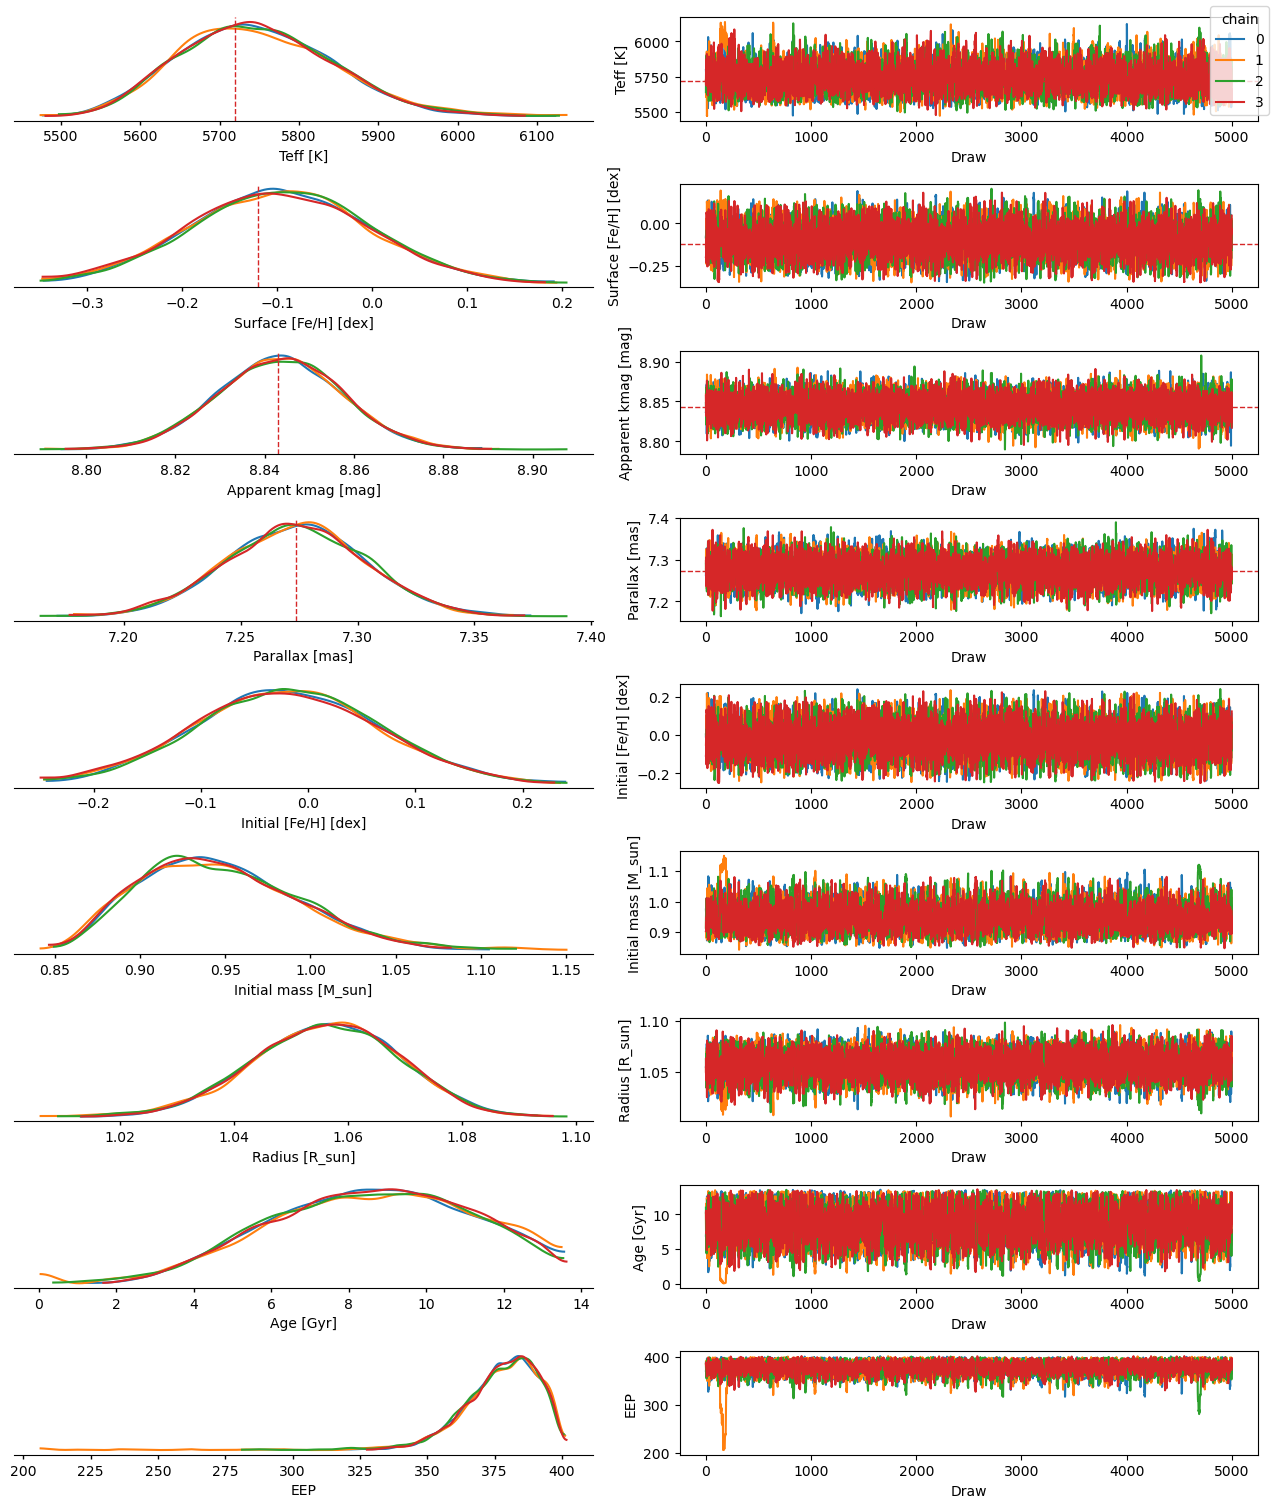

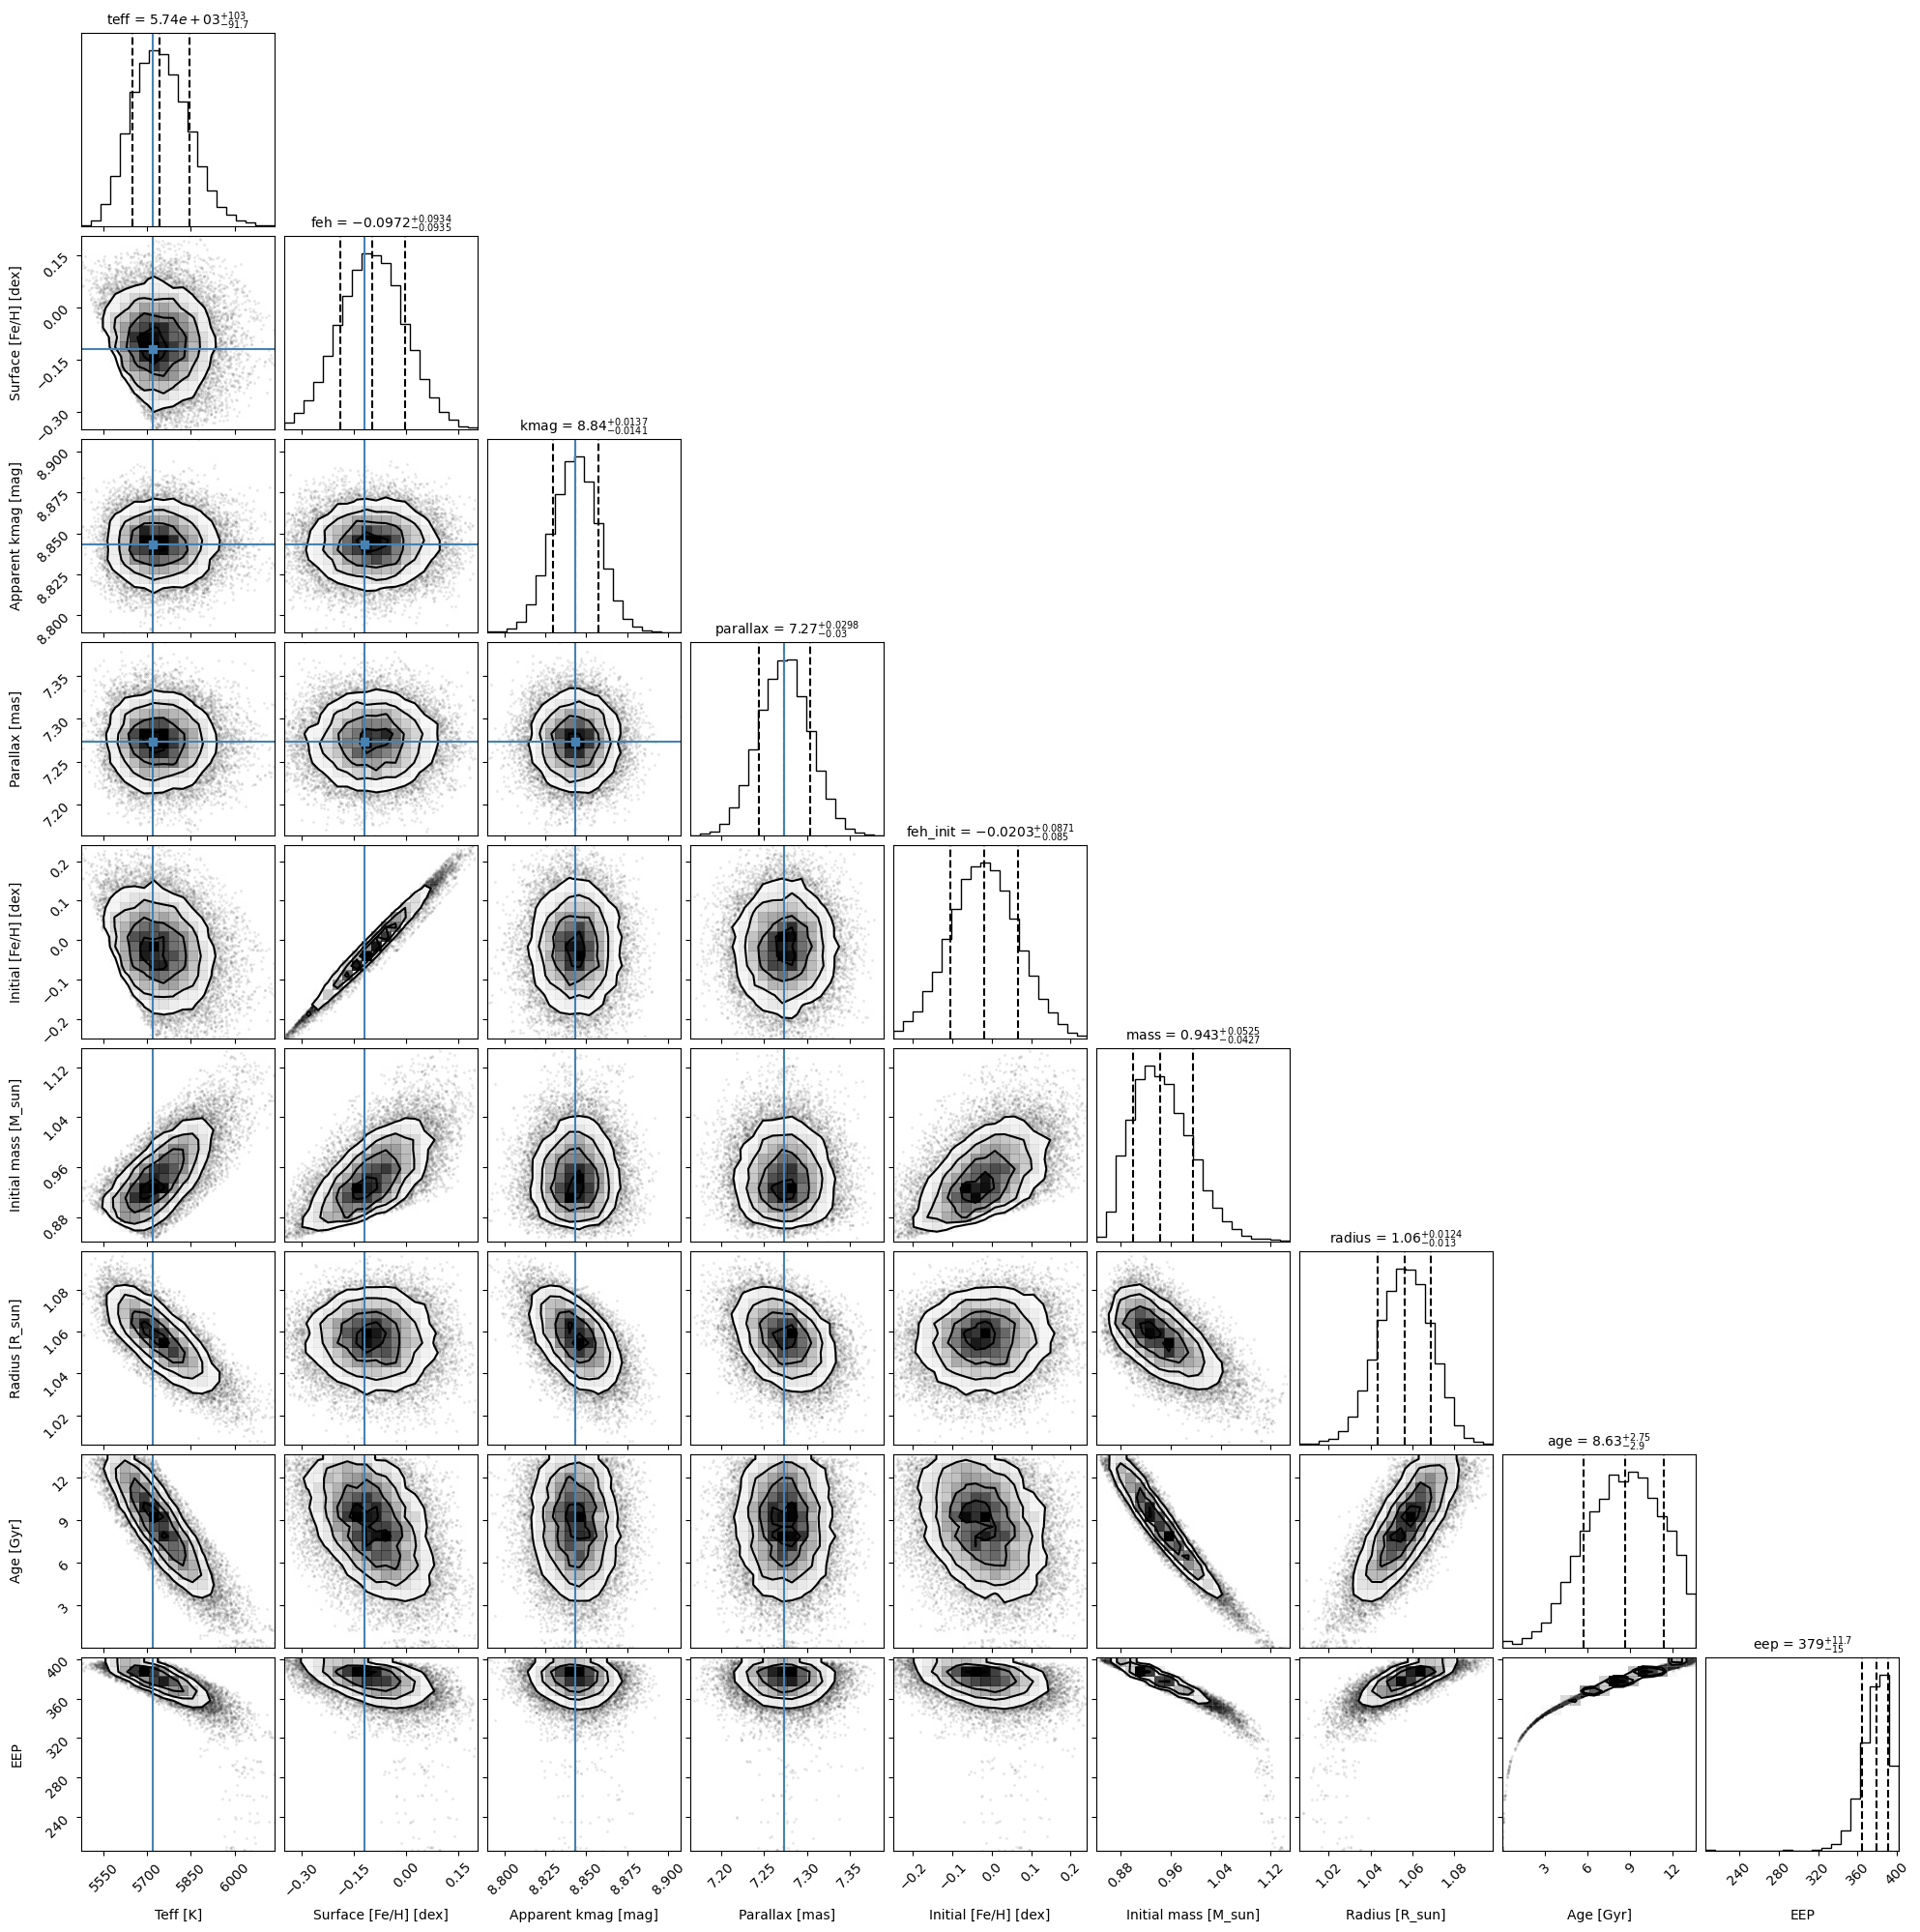

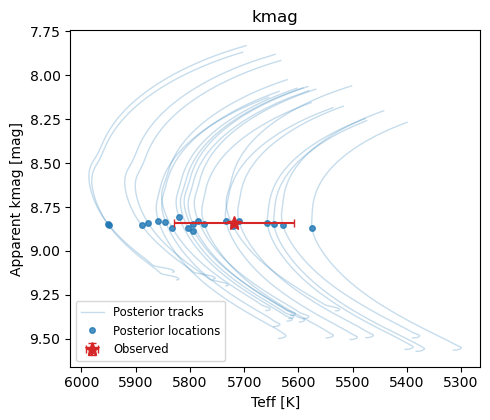

In [7]:
outkeys = [*observations, "feh_init", "mass", "radius", "age", "eep"]
figures = mf.plot_diagnostics(idata, keys=outkeys, output_dir=result_dir)

### Compare with the saved MIST v1.2 NUTS posterior

Load `results/track_nuts` from `fit_track.ipynb` and the v2.5 run saved above.
Use the same variables and corner style as the preceding plot, with common
axis ranges for both posteriors. Blue is v1.2; orange is v2.5. Diagonal titles
show the v2.5 median and 16th/84th percentiles. The observed reference lines
are shared. The comparison is saved as `corner_v12_v25.png` in `result_dir`.


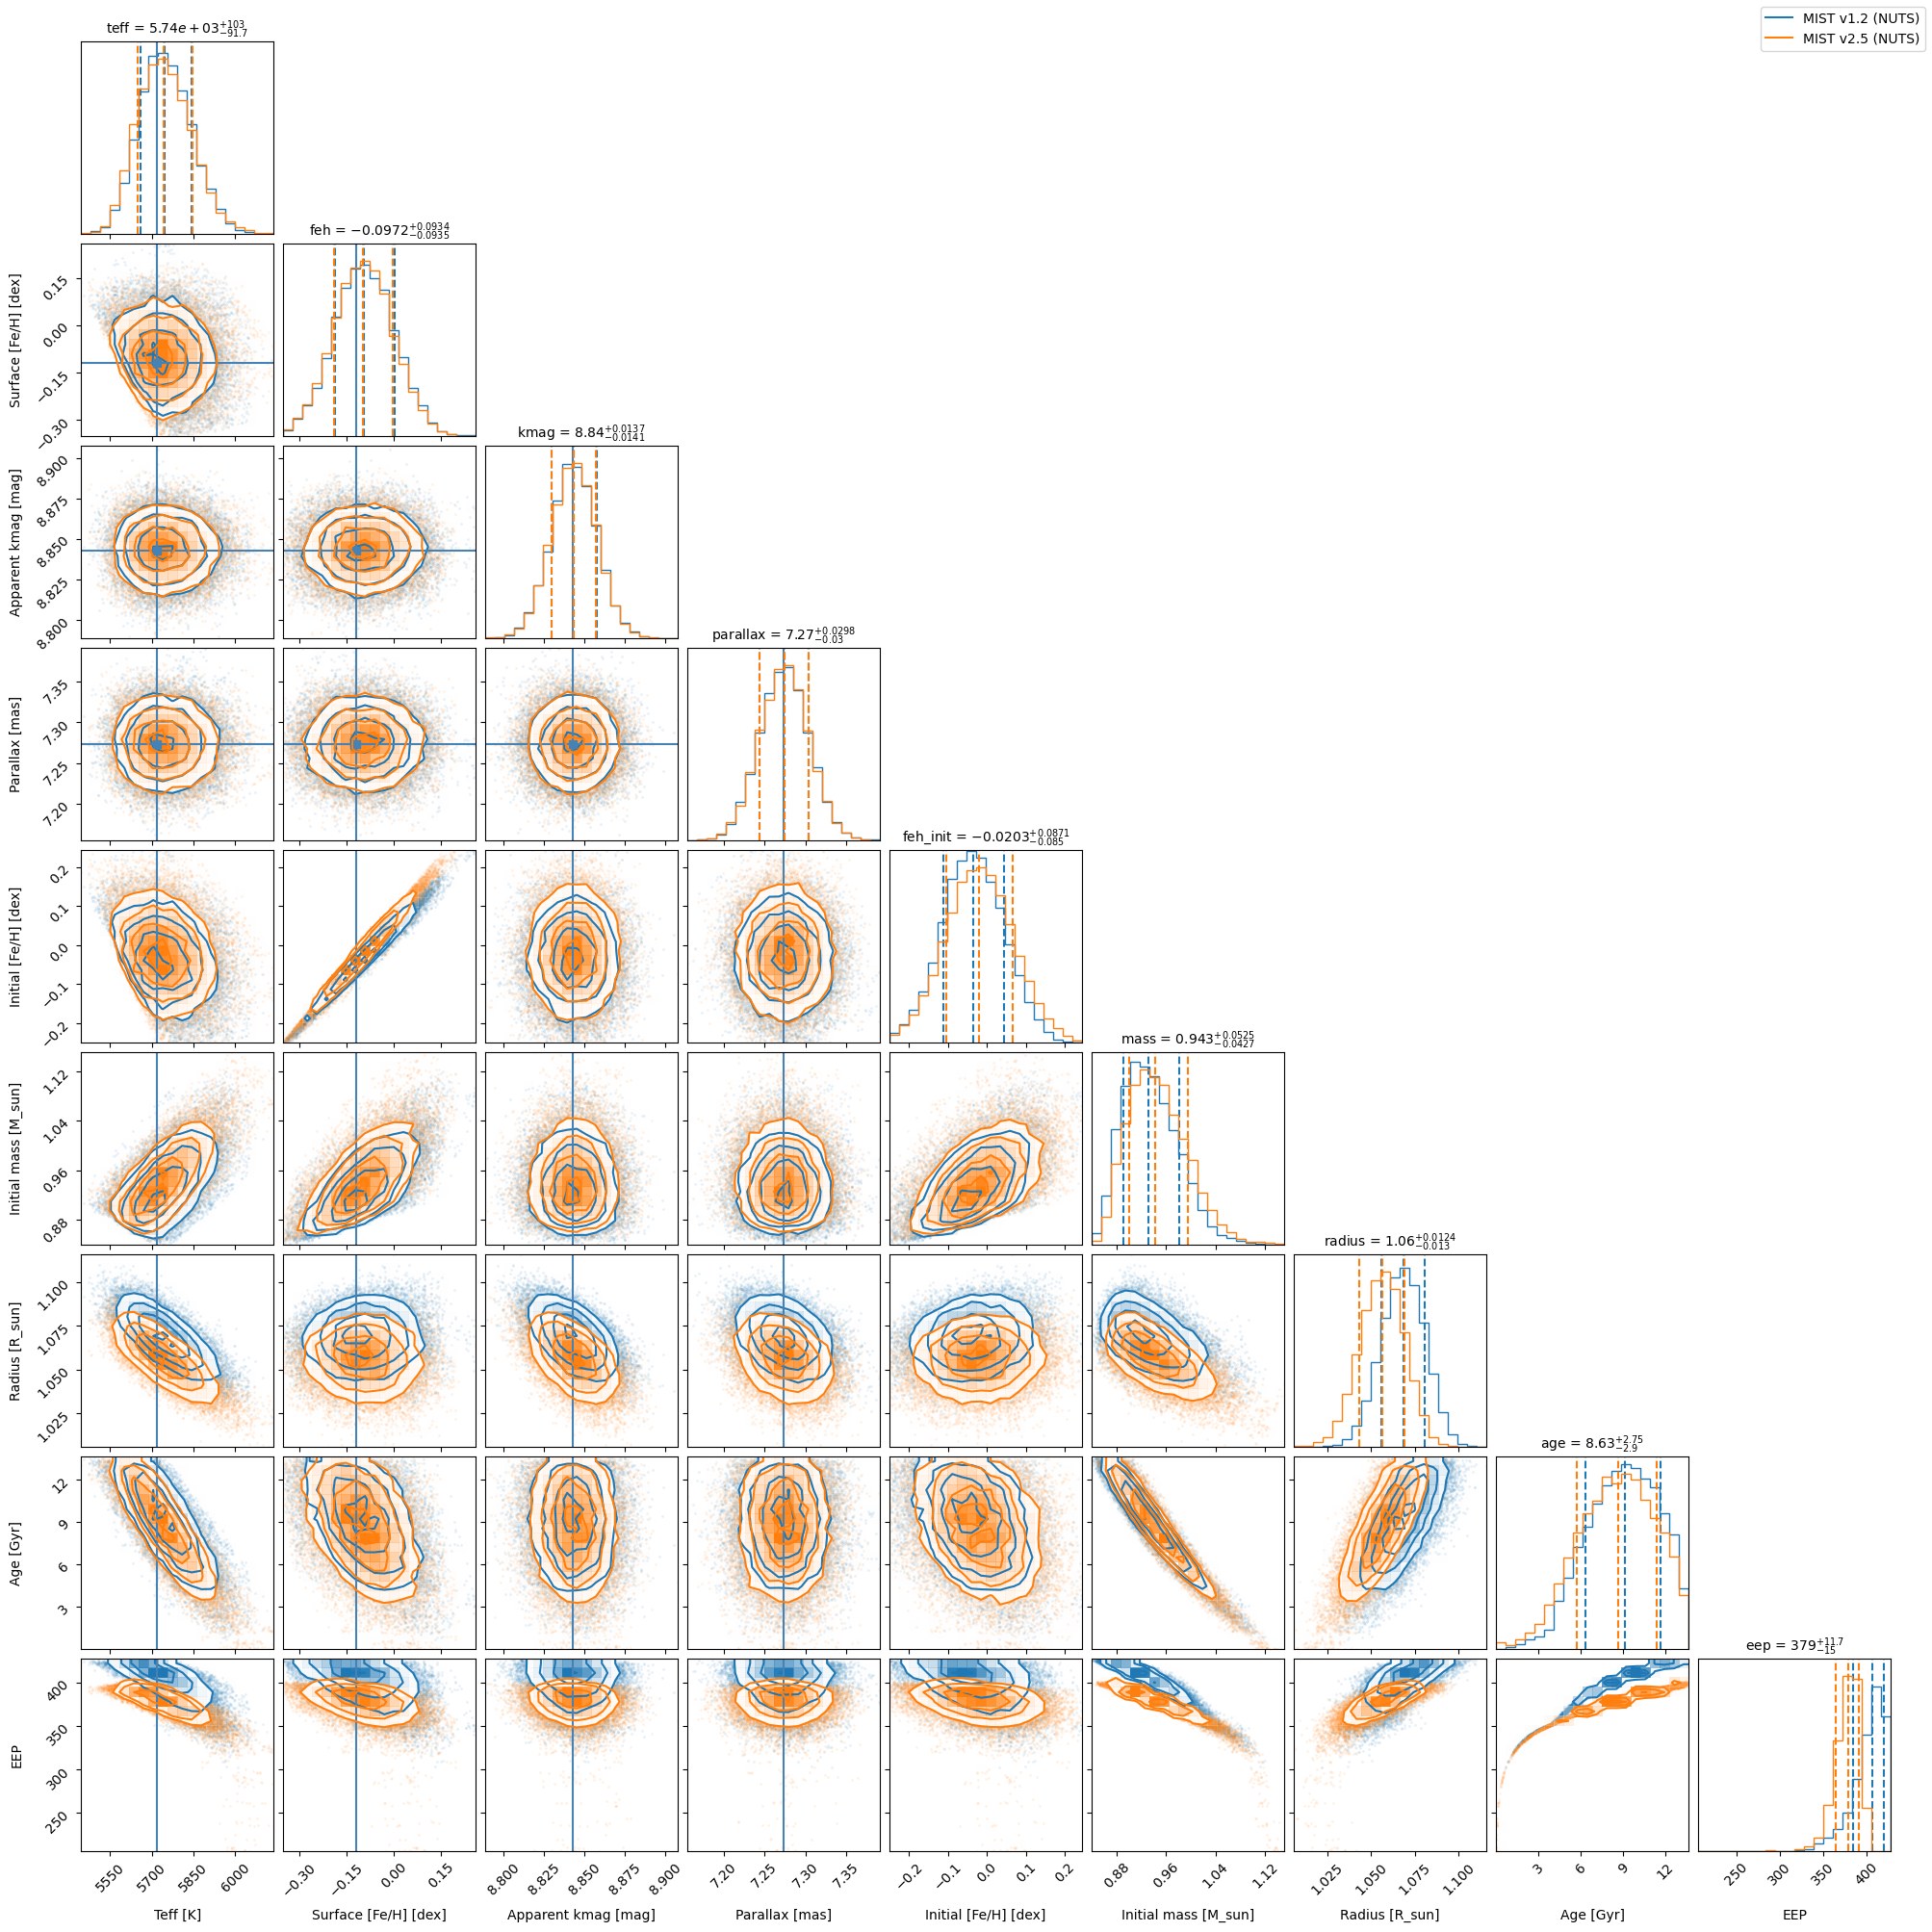

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from jaxstar.mistfit import load_result, plot_corner

idata_v12 = load_result(Path("results/track_nuts"))
idata_v25 = load_result(result_dir)

# Common limits and histogram bins include both saved posteriors.
corner_ranges = []
for key in outkeys:
    values = np.concatenate([
        idata_v12.posterior[key].values.ravel(),
        idata_v25.posterior[key].values.ravel(),
    ])
    lo, hi = float(values.min()), float(values.max())
    if lo == hi:
        width = max(abs(lo), 1.) * 1e-3
        lo, hi = lo - width, hi + width
    corner_ranges.append((lo, hi))

corner_comparison = plot_corner(
    idata_v12, keys=outkeys, color="C0", range=corner_ranges,
)
corner_comparison = plot_corner(
    idata_v25, keys=outkeys, color="C1", range=corner_ranges,
    fig=corner_comparison, show_observations=False,
)
corner_comparison.legend(
    handles=[
        Line2D([], [], color="C0", label="MIST v1.2 (NUTS)"),
        Line2D([], [], color="C1", label="MIST v2.5 (NUTS)"),
    ],
    loc="upper right",
)
comparison_path = result_dir / "corner_v12_v25.png"
corner_comparison.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.show()


### Structural quantities from the fitted posterior

Use `mf.physical_model` and `idata` above to compute all 66 native columns in `structure_samples`, then select six quantities for the corner plot: envelope thickness, envelope mass, local turnover time one mixing length above the envelope base, global turnover time, total moment of inertia, and the apsidal constant k2. Turnover times are shown in days and moment of inertia in units of 10^53 g cm². Nonfinite or nonpositive diagnostics are excluded together from the corner plot.


See the [native-column reference](../../docs/mistgrid-columns.md) for the full list of 66 columns, their contents and units.


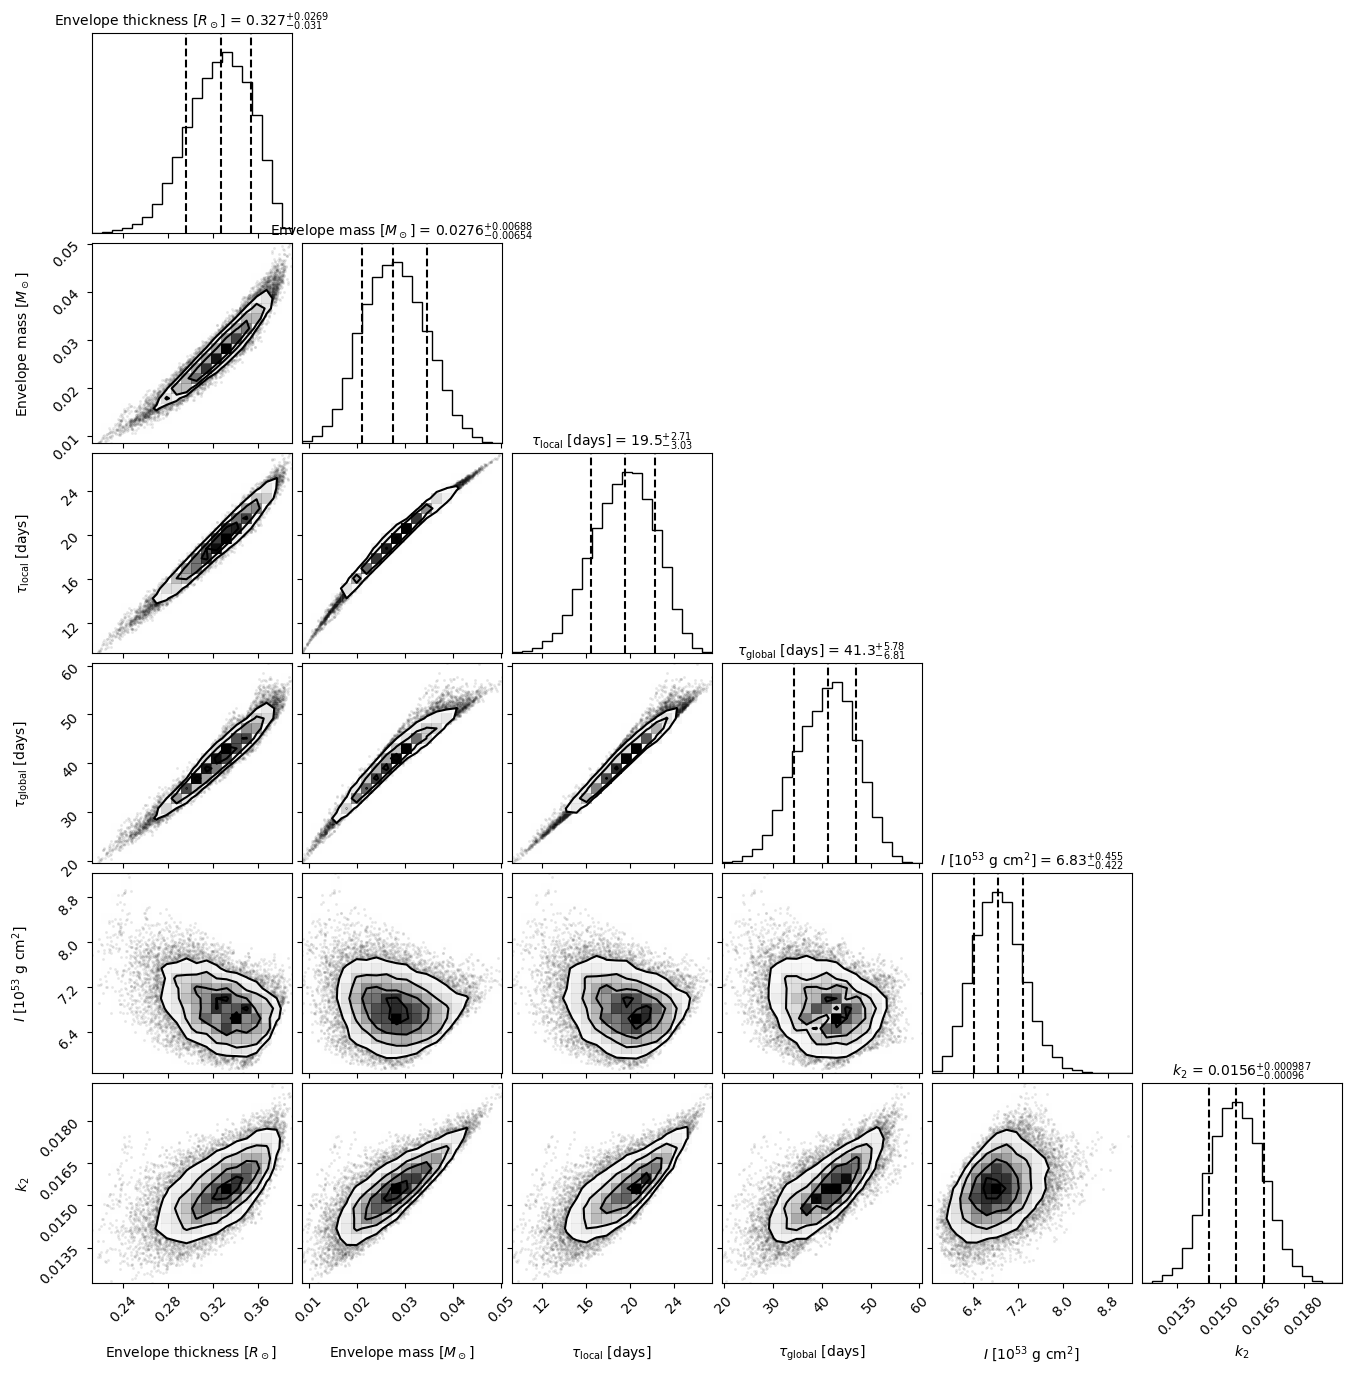

In [9]:
import corner
import numpy as np
import matplotlib.pyplot as plt

posterior = idata.posterior
# Predict all 66 native columns for the posterior samples.
structure_samples = mf.physical_model(
    {
        "mass_init": posterior["mass"].values,
        "feh_init": posterior["feh_init"].values,
        "eep": posterior["eep"].values,
    },
    keys=tuple(mf.physical_model.metadata["native_columns"]),
)

# Select six quantities for the corner plot.
p = structure_samples
corner_samples = np.column_stack([
    np.asarray(value).ravel() for value in (
        p["conv_env_top_radius"] - p["conv_env_bot_radius"],
        p["conv_env_top_mass"] - p["conv_env_bot_mass"],
        p["conv_env_turnover_time_l_t"] / 86400.,
        p["conv_env_turnover_time_g"] / 86400.,
        p["total_moment_of_inertia"] / 1e53,
        p["apsidal_constant_k2"],
    )
])
# Exclude unsupported predictions and absent-envelope zeros from the plot.
valid = np.all(np.isfinite(corner_samples) & (corner_samples > 0), axis=1)
if not valid.all():
    print(f"Corner uses {valid.sum()} / {len(valid)} posterior draws.")
structure_corner = corner.corner(
    corner_samples[valid],
    labels=[
        r"Envelope thickness [$R_\odot$]", r"Envelope mass [$M_\odot$]",
        r"$\tau_\mathrm{local}$ [days]", r"$\tau_\mathrm{global}$ [days]",
        r"$I$ [$10^{53}$ g cm$^2$]", r"$k_2$",
    ],
    quantiles=(.16, .5, .84), show_titles=True, title_fmt=".3g",
    label_kwargs={"fontsize": 10}, title_kwargs={"fontsize": 10},
)
plt.show()
